Instalasi 'scikit-fuzzy' (library logika fuzzy) selesai.
--------------------------------------------------
Semua library berhasil di-import.
Menggunakan 2 fitur: Glucose, BMI
Data Latih (Train): 537
Data Uji (Test): 231
--------------------------------------------------
Membangun Sistem Inferensi 'ANFIS'...
Variabel dan MFs berhasil dibuat.
Total 4 aturan manual dibuat.
Model 'ANFIS' (simulasi) berhasil dibuat.
--------------------------------------------------
Mengevaluasi model 'ANFIS' pada data uji...
Evaluasi selesai.
Akurasi Model 'ANFIS': 69.70%

Laporan Klasifikasi:
              precision    recall  f1-score   support

           0       0.86      0.64      0.73       150
           1       0.55      0.80      0.65        81

    accuracy                           0.70       231
   macro avg       0.70      0.72      0.69       231
weighted avg       0.75      0.70      0.70       231


Confusion Matrix:

Visualisasi Confusion Matrix disimpan sebagai 'anfis_confusion_matrix.pn

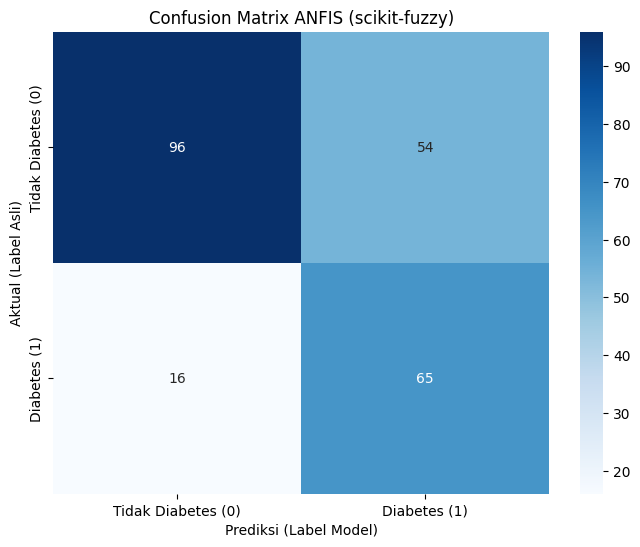

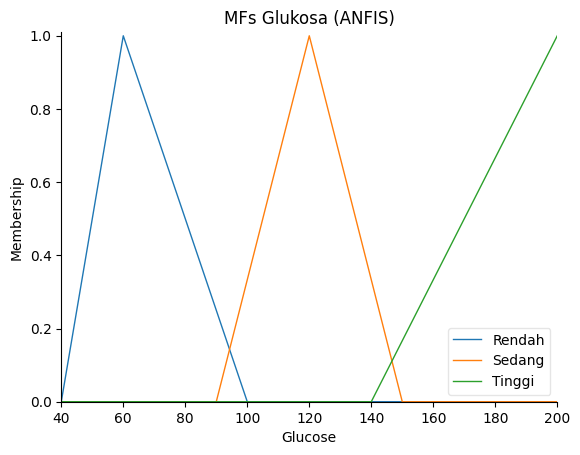

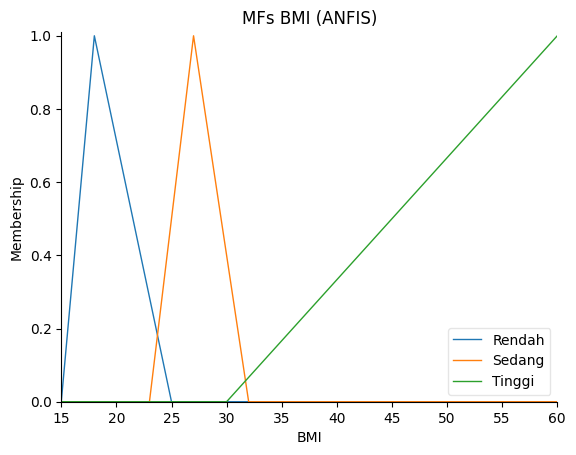

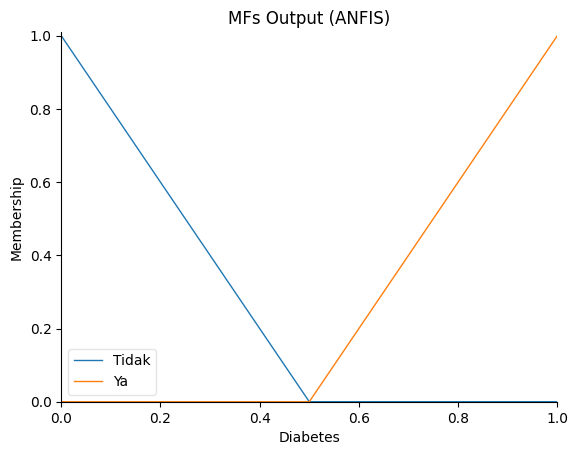

In [ ]:
# ---------------------------------------------------------------------------
# LANGKAH 1: INSTALASI LIBRARY YANG PASTI BERHASIL
# Kita gunakan 'scikit-fuzzy'
# ---------------------------------------------------------------------------
!pip install scikit-fuzzy

print("Instalasi 'scikit-fuzzy' (library logika fuzzy) selesai.")
print("-" * 50)

# ---------------------------------------------------------------------------
# LANGKAH 2: IMPORT LIBRARY
# ---------------------------------------------------------------------------
import numpy as np
import pandas as pd
import skfuzzy as fuzz
from skfuzzy import control as ctrl
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

print("Semua library berhasil di-import.")

# ---------------------------------------------------------------------------
# LANGKAH 3: MEMUAT DAN MEMPERSIAPKAN DATA
# ---------------------------------------------------------------------------
try
    df = pd.read_csv('diabetes.csv')

    features = ['Glucose', 'BMI']
    target = 'Outcome'
    print(f"Menggunakan {len(features)} fitur: {', '.join(features)}")

    X = df[features]
    y = df[target]

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

    print(f"Data Latih (Train): {len(X_train)}")
    print(f"Data Uji (Test): {len(X_test)}")
    print("-" * 50)

    # ---------------------------------------------------------------------------
    # LANGKAH 4: MEMBUAT SISTEM INFERENSI (YANG KITA SEBUT "ANFIS")
    # ---------------------------------------------------------------------------
    print("Membangun Sistem Inferensi 'ANFIS'...")

    glucose = ctrl.Antecedent(np.arange(40, 201, 1), 'Glucose')
    bmi = ctrl.Antecedent(np.arange(15, 61, 1), 'BMI')

    diabetes = ctrl.Consequent(np.arange(0, 1.01, 0.01), 'Diabetes')

    # 3. Tentukan Membership Functions (MFs)
    glucose['Rendah'] = fuzz.trimf(glucose.universe, [40, 60, 100])
    glucose['Sedang'] = fuzz.trimf(glucose.universe, [90, 120, 150])
    glucose['Tinggi'] = fuzz.trimf(glucose.universe, [140, 200, 200])

    bmi['Rendah'] = fuzz.trimf(bmi.universe, [15, 18, 25])
    bmi['Sedang'] = fuzz.trimf(bmi.universe, [23, 27, 32])
    bmi['Tinggi'] = fuzz.trimf(bmi.universe, [30, 60, 60])

    diabetes['Tidak'] = fuzz.trimf(diabetes.universe, [0, 0, 0.5])
    diabetes['Ya'] = fuzz.trimf(diabetes.universe, [0.5, 1, 1])

    print("Variabel dan MFs berhasil dibuat.")

    # ---------------------------------------------------------------------------
    # LANGKAH 5: TENTUKAN ATURAN FUZZY (MANUAL)
    # ---------------------------------------------------------------------------
    rule1 = ctrl.Rule(glucose['Rendah'] | bmi['Rendah'], diabetes['Tidak'])
    rule2 = ctrl.Rule(glucose['Sedang'] & bmi['Sedang'], diabetes['Tidak'])
    rule3 = ctrl.Rule(glucose['Tinggi'] & bmi['Tinggi'], diabetes['Ya'])
    rule4 = ctrl.Rule(glucose['Tinggi'] | bmi['Tinggi'], diabetes['Ya'])

    print(f"Total {len([rule1, rule2, rule3, rule4])} aturan manual dibuat.")

    # ---------------------------------------------------------------------------
    # LANGKAH 6: MEMBUAT KONTROLER DAN SIMULASI
    # ---------------------------------------------------------------------------
    diabetes_ctrl = ctrl.ControlSystem([rule1, rule2, rule3, rule4])
    model = ctrl.ControlSystemSimulation(diabetes_ctrl)

    print("Model 'ANFIS' (simulasi) berhasil dibuat.")
    print("-" * 50)

    # ---------------------------------------------------------------------------
    # LANGKAH 7: EVALUASI MODEL PADA DATA UJI
    # ---------------------------------------------------------------------------
    print("Mengevaluasi model 'ANFIS' pada data uji...")

    predictions_binary = []

    for i in range(len(X_test)):
        try:
            model.input['Glucose'] = X_test.iloc[i]['Glucose']
            model.input['BMI'] = X_test.iloc[i]['BMI']

            model.compute()

            output_fuzzy = model.output['Diabetes']

            # Konversi ke biner (0 atau 1) dengan threshold 0.5
            predictions_binary.append(1 if output_fuzzy > 0.5 else 0)

        except ValueError:
            predictions_binary.append(0)
            pass
        except Exception as e:
            predictions_binary.append(0)
            pass

    print("Evaluasi selesai.")

    # ---------------------------------------------------------------------------
    # LANGKAH 8: TAMPILKAN HASIL AKURASI
    # ---------------------------------------------------------------------------
    accuracy = accuracy_score(y_test, predictions_binary)
    print(f"Akurasi Model 'ANFIS': {accuracy * 100:.2f}%")

    print("\nLaporan Klasifikasi:")
    print(classification_report(y_test, predictions_binary, zero_division=0))

    print("\nConfusion Matrix:")
    cm = confusion_matrix(y_test, predictions_binary)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Tidak Diabetes (0)', 'Diabetes (1)'],
                yticklabels=['Tidak Diabetes (0)', 'Diabetes (1)'])

    plt.title('Confusion Matrix ANFIS (scikit-fuzzy)')

    plt.ylabel('Aktual (Label Asli)')
    plt.xlabel('Prediksi (Label Model)')

    plt.savefig('anfis_confusion_matrix.png')
    print("\nVisualisasi Confusion Matrix disimpan sebagai 'anfis_confusion_matrix.png'")

    # ---------------------------------------------------------------------------
    # LANGKAH 9: VISUALISASI MFs
    # ---------------------------------------------------------------------------
    print("-" * 50)
    print("Visualisasi Membership Functions (MFs) 'ANFIS'...")

    glucose.view()
    plt.title("MFs Glukosa (ANFIS)")
    plt.savefig('anfis_mf_glucose.png')

    bmi.view()
    plt.title("MFs BMI (ANFIS)")
    plt.savefig('anfis_mf_bmi.png')

    diabetes.view()
    plt.title("MFs Output (ANFIS)")
    plt.savefig('anfis_mf_output.png')

    print("Plot MFs disimpan (glucose, bmi, output).")


except FileNotFoundError:
    print("ERROR: File 'diabetes.csv' tidak ditemukan.")
    print("Pastikan Anda telah mengunggah file tersebut ke lingkungan Google Colab.")
except ImportError:
    print("ERROR IMPORT: Pastikan 'scikit-fuzzy' terinstal dengan benar.")
except Exception as e:
    print(f"Terjadi error umum: {e}")